In [27]:
import re
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [28]:
df=pd.read_csv("laptop.csv")

In [29]:
df

,Unnamed: 0,Brand,Brand_title,Processor,RAM,SSD,Display,Price,original_price,Discount,Ratings
0,0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5 Processor (13th Gen),8.0,5.0,5.0,"55,311","78,189",29.0,4.4
1,1,Samsung Galaxy Book4 Metal Intel Core i3 13th ...,Samsung,8 GB LPDDR4X RAM,8.0,8.0,8.0,"51,990","57,499",9.0,4.4
2,2,"Acer Aspire 15 MS Office 2024 + M365 Basic, AM...",Acer,64 bit Windows 11 Operating System,8.0,64.0,64.0,"39,990","74,999",46.0,3.7
3,3,Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 ...,Acer,512 GB SSD,16.0,512.0,512.0,"59,990","78,999",24.0,4.5
4,4,ASUS Vivobook 15 (2025) with Office 2024 + M36...,ASUS,39.62 cm (15.6 Inch) Display,8.0,62.0,62.0,"42,990","50,990",15.0,4.3
...,...,...,...,...,...,...,...,...,...,...,...
1568,1568,NaN,NaN,16 GB DDR4 RAM,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1569,1569,NaN,NaN,Windows 11 Operating System,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1570,1570,NaN,NaN,512 GB SSD,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1571,1571,NaN,NaN,39.62 cm (15.6 Inch) Display,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
df.drop(columns=['Unnamed: 0'],inplace=True)

In [31]:
df.columns

Index(['Brand', 'Brand_title', 'Processor', 'RAM', 'SSD', 'Display', 'Price',
       'original_price', 'Discount', 'Ratings'],
      dtype='object')

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1573 entries, 0 to 1572
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Brand           234 non-null    object 
 1   Brand_title     240 non-null    object 
 2   Processor       1568 non-null   object 
 3   RAM             240 non-null    float64
 4   SSD             1482 non-null   float64
 5   Display         1482 non-null   float64
 6   Price           240 non-null    object 
 7   original_price  221 non-null    object 
 8   Discount        261 non-null    float64
 9   Ratings         376 non-null    float64
dtypes: float64(5), object(5)
memory usage: 123.0+ KB


### 2. Data Cleaning

In [33]:
df.isnull().sum()

Brand             1339
Brand_title       1333
Processor            5
RAM               1333
SSD                 91
Display             91
Price             1333
original_price    1352
Discount          1312
Ratings           1197
dtype: int64

In [34]:
df['Price']=df['Price'].str.replace(",","")
df['original_price']=df['original_price'].str.replace(",","")

### Changing datatype

In [35]:
df["original_price"] = df["original_price"].astype("float64")
df["Price"] = df["Price"].astype("float64")

### Handling Missing Values

In [36]:
df['Display'] = df['Display'].fillna(df['Display'].mean())
df['RAM'] = df['RAM'].fillna(df['RAM'].median())
df['SSD'] = df['SSD'].fillna(df['SSD'].median())
df['Price'] = df['Price'].fillna(df['Price'].median())
df['original_price'] = df['original_price'].fillna(df['original_price'].median())
df['Discount'] = df['Discount'].fillna(df['Discount'].median())
df['Ratings'] = df['Ratings'].fillna(df['Ratings'].median())

In [37]:
df.isnull().sum()

Brand             1339
Brand_title       1333
Processor            5
RAM                  0
SSD                  0
Display              0
Price                0
original_price       0
Discount             0
Ratings              0
dtype: int64

In [38]:
df.dropna(subset=['Processor'],inplace=True)

In [39]:
df['Brand'] = df['Brand'].fillna(df['Brand'].mode()[0])

In [40]:
df['Brand'].unique()

array(['Samsung Galaxy Book4 Metal Intel Core i5 13th Gen 1335U',
       'Samsung Galaxy Book4 Metal Intel Core i3 13th Gen 1315U',
       'Acer Aspire 15 MS Office 2024 + M365 Basic, AMD Ryzen 3 Quad Core 7330U',
       'Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 210H',
       'ASUS Vivobook 15 (2025) with Office 2024 + M365 Basic* Intel Core i3 13th Gen',
       'Samsung Galaxy Book5 AI Metal Intel Core Ultra 7 255U',
       'walker Intel Celeron Dual Core Intel N4020',
       'MICROSOFT Surface Laptop 13.8 Inch Snapdragon X2 Plus',
       'Acer One 14 AMD Ryzen 3 Quad Core 7320U',
       'Acer Aspire 3 Intel Pentium Quad Core N6000',
       'Samsung Galaxy Book5 AI Metal Intel Core Ultra 5 225U',
       'Lenovo IdeaPad Slim 3 Intel Core i5 13th Gen 13420H',
       'ASUS Vivobook 14 (2025) with Office 2024 + M365 Basic*, Backlit Keyboard, Snapdragon X',
       'MICROSOFT Surface Laptop 15 Inch Snapdragon X2 Elite',
       'Acer Aspire 7 (i7 14th Gen) Intel Core 7 240H',
       'AS

In [41]:
df['Brand_title'] = df['Brand_title'].fillna(df['Brand_title'].mode()[0])
df

,Brand,Brand_title,Processor,RAM,SSD,Display,Price,original_price,Discount,Ratings
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5 Processor (13th Gen),8.0,5.0,5.000000,55311.0,78189.0,29.0,4.40
1,Samsung Galaxy Book4 Metal Intel Core i3 13th ...,Samsung,8 GB LPDDR4X RAM,8.0,8.0,8.000000,51990.0,57499.0,9.0,4.40
2,"Acer Aspire 15 MS Office 2024 + M365 Basic, AM...",Acer,64 bit Windows 11 Operating System,8.0,64.0,64.000000,39990.0,74999.0,46.0,3.70
3,Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 ...,Acer,512 GB SSD,16.0,512.0,512.000000,59990.0,78999.0,24.0,4.50
4,ASUS Vivobook 15 (2025) with Office 2024 + M36...,ASUS,39.62 cm (15.6 Inch) Display,8.0,62.0,62.000000,42990.0,50990.0,15.0,4.30
...,...,...,...,...,...,...,...,...,...,...
1568,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,16 GB DDR4 RAM,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1569,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,Windows 11 Operating System,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1570,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,512 GB SSD,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1571,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,39.62 cm (15.6 Inch) Display,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35


In [42]:
df.isnull().sum()

Brand             0
Brand_title       0
Processor         0
RAM               0
SSD               0
Display           0
Price             0
original_price    0
Discount          0
Ratings           0
dtype: int64

In [43]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1568     True
1569     True
1570     True
1571     True
1572     True
Length: 1568, dtype: bool

In [44]:
df.drop_duplicates(inplace=True)
df

,Brand,Brand_title,Processor,RAM,SSD,Display,Price,original_price,Discount,Ratings
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5 Processor (13th Gen),8.0,5.0,5.000000,55311.0,78189.0,29.0,4.40
1,Samsung Galaxy Book4 Metal Intel Core i3 13th ...,Samsung,8 GB LPDDR4X RAM,8.0,8.0,8.000000,51990.0,57499.0,9.0,4.40
2,"Acer Aspire 15 MS Office 2024 + M365 Basic, AM...",Acer,64 bit Windows 11 Operating System,8.0,64.0,64.000000,39990.0,74999.0,46.0,3.70
3,Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 ...,Acer,512 GB SSD,16.0,512.0,512.000000,59990.0,78999.0,24.0,4.50
4,ASUS Vivobook 15 (2025) with Office 2024 + M36...,ASUS,39.62 cm (15.6 Inch) Display,8.0,62.0,62.000000,42990.0,50990.0,15.0,4.30
...,...,...,...,...,...,...,...,...,...,...
1560,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,Intel Core i5 Processor (8th Gen),16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1562,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,64 bit Windows 10 Operating System,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1563,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,1 TB HDD,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1565,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,"HP Audio Switch, HP Support Assistant",16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35


In [45]:
df["Brand_title"].value_counts()

Brand_title
ASUS         734
Samsung       58
HP            34
Acer          31
Lenovo        25
DELL           7
Infinix        5
MICROSOFT      4
MSI            4
walker         2
Primebook      2
ZEBRONICS      2
MOTOROLA       1
Name: count, dtype: int64

In [46]:
df.duplicated().sum()

np.int64(0)

### Feature Engineering


In [47]:
df

,Brand,Brand_title,Processor,RAM,SSD,Display,Price,original_price,Discount,Ratings
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5 Processor (13th Gen),8.0,5.0,5.000000,55311.0,78189.0,29.0,4.40
1,Samsung Galaxy Book4 Metal Intel Core i3 13th ...,Samsung,8 GB LPDDR4X RAM,8.0,8.0,8.000000,51990.0,57499.0,9.0,4.40
2,"Acer Aspire 15 MS Office 2024 + M365 Basic, AM...",Acer,64 bit Windows 11 Operating System,8.0,64.0,64.000000,39990.0,74999.0,46.0,3.70
3,Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 ...,Acer,512 GB SSD,16.0,512.0,512.000000,59990.0,78999.0,24.0,4.50
4,ASUS Vivobook 15 (2025) with Office 2024 + M36...,ASUS,39.62 cm (15.6 Inch) Display,8.0,62.0,62.000000,42990.0,50990.0,15.0,4.30
...,...,...,...,...,...,...,...,...,...,...
1560,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,Intel Core i5 Processor (8th Gen),16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1562,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,64 bit Windows 10 Operating System,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1563,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,1 TB HDD,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35
1565,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,"HP Audio Switch, HP Support Assistant",16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35


In [48]:
df["Price_Category"] = pd.cut(df["Price"],
 bins=[0, 40000, 70000, 200000],
labels=["Budget", "Mid-Range", "Premium"]
)

In [49]:
df

,Brand,Brand_title,Processor,RAM,SSD,Display,Price,original_price,Discount,Ratings,Price_Category
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5 Processor (13th Gen),8.0,5.0,5.000000,55311.0,78189.0,29.0,4.40,Mid-Range
1,Samsung Galaxy Book4 Metal Intel Core i3 13th ...,Samsung,8 GB LPDDR4X RAM,8.0,8.0,8.000000,51990.0,57499.0,9.0,4.40,Mid-Range
2,"Acer Aspire 15 MS Office 2024 + M365 Basic, AM...",Acer,64 bit Windows 11 Operating System,8.0,64.0,64.000000,39990.0,74999.0,46.0,3.70,Budget
3,Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 ...,Acer,512 GB SSD,16.0,512.0,512.000000,59990.0,78999.0,24.0,4.50,Mid-Range
4,ASUS Vivobook 15 (2025) with Office 2024 + M36...,ASUS,39.62 cm (15.6 Inch) Display,8.0,62.0,62.000000,42990.0,50990.0,15.0,4.30,Mid-Range
...,...,...,...,...,...,...,...,...,...,...,...
1560,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,Intel Core i5 Processor (8th Gen),16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range
1562,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,64 bit Windows 10 Operating System,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range
1563,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,1 TB HDD,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range
1565,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,"HP Audio Switch, HP Support Assistant",16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range


In [50]:
def categorize_ram(df):
    """
    Categorize RAM into Low, Medium, and High.
    """
    df["RAM_Category"] = pd.cut(
        df["RAM"],
        bins=[0, 8, 16, 128],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )
    return df

df = categorize_ram(df)

print(df[["RAM", "RAM_Category"]].head())

    RAM RAM_Category
0   8.0          Low
1   8.0          Low
2   8.0          Low
3  16.0       Medium
4   8.0          Low


In [51]:
df

,Brand,Brand_title,Processor,RAM,SSD,Display,Price,original_price,Discount,Ratings,Price_Category,RAM_Category
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5 Processor (13th Gen),8.0,5.0,5.000000,55311.0,78189.0,29.0,4.40,Mid-Range,Low
1,Samsung Galaxy Book4 Metal Intel Core i3 13th ...,Samsung,8 GB LPDDR4X RAM,8.0,8.0,8.000000,51990.0,57499.0,9.0,4.40,Mid-Range,Low
2,"Acer Aspire 15 MS Office 2024 + M365 Basic, AM...",Acer,64 bit Windows 11 Operating System,8.0,64.0,64.000000,39990.0,74999.0,46.0,3.70,Budget,Low
3,Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 ...,Acer,512 GB SSD,16.0,512.0,512.000000,59990.0,78999.0,24.0,4.50,Mid-Range,Medium
4,ASUS Vivobook 15 (2025) with Office 2024 + M36...,ASUS,39.62 cm (15.6 Inch) Display,8.0,62.0,62.000000,42990.0,50990.0,15.0,4.30,Mid-Range,Low
...,...,...,...,...,...,...,...,...,...,...,...,...
1560,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,Intel Core i5 Processor (8th Gen),16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium
1562,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,64 bit Windows 10 Operating System,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium
1563,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,1 TB HDD,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium
1565,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,"HP Audio Switch, HP Support Assistant",16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium


In [52]:
df

,Brand,Brand_title,Processor,RAM,SSD,Display,Price,original_price,Discount,Ratings,Price_Category,RAM_Category
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5 Processor (13th Gen),8.0,5.0,5.000000,55311.0,78189.0,29.0,4.40,Mid-Range,Low
1,Samsung Galaxy Book4 Metal Intel Core i3 13th ...,Samsung,8 GB LPDDR4X RAM,8.0,8.0,8.000000,51990.0,57499.0,9.0,4.40,Mid-Range,Low
2,"Acer Aspire 15 MS Office 2024 + M365 Basic, AM...",Acer,64 bit Windows 11 Operating System,8.0,64.0,64.000000,39990.0,74999.0,46.0,3.70,Budget,Low
3,Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 ...,Acer,512 GB SSD,16.0,512.0,512.000000,59990.0,78999.0,24.0,4.50,Mid-Range,Medium
4,ASUS Vivobook 15 (2025) with Office 2024 + M36...,ASUS,39.62 cm (15.6 Inch) Display,8.0,62.0,62.000000,42990.0,50990.0,15.0,4.30,Mid-Range,Low
...,...,...,...,...,...,...,...,...,...,...,...,...
1560,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,Intel Core i5 Processor (8th Gen),16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium
1562,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,64 bit Windows 10 Operating System,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium
1563,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,1 TB HDD,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium
1565,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,"HP Audio Switch, HP Support Assistant",16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium


In [53]:
df["SSD_Category"] = pd.cut(
    df["SSD"],
    bins=[0, 256, 512, 2048],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print(df[["SSD", "SSD_Category"]].head())

def categorize_ssd(ssd):
    if ssd <= 256:
        return "Low"
    elif ssd <= 512:
        return "Medium"
    else:
        return "High"

df["SSD_Category"] = df["SSD"].apply(categorize_ssd)

print(df[["SSD", "SSD_Category"]].head())

     SSD SSD_Category
0    5.0          Low
1    8.0          Low
2   64.0          Low
3  512.0       Medium
4   62.0          Low
     SSD SSD_Category
0    5.0          Low
1    8.0          Low
2   64.0          Low
3  512.0       Medium
4   62.0          Low


In [54]:
df

,Brand,Brand_title,Processor,RAM,SSD,Display,Price,original_price,Discount,Ratings,Price_Category,RAM_Category,SSD_Category
0,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,Samsung,Intel Core i5 Processor (13th Gen),8.0,5.0,5.000000,55311.0,78189.0,29.0,4.40,Mid-Range,Low,Low
1,Samsung Galaxy Book4 Metal Intel Core i3 13th ...,Samsung,8 GB LPDDR4X RAM,8.0,8.0,8.000000,51990.0,57499.0,9.0,4.40,Mid-Range,Low,Low
2,"Acer Aspire 15 MS Office 2024 + M365 Basic, AM...",Acer,64 bit Windows 11 Operating System,8.0,64.0,64.000000,39990.0,74999.0,46.0,3.70,Budget,Low,Low
3,Acer Aspire 15 Lite(i5 14th Gen) Intel Core 5 ...,Acer,512 GB SSD,16.0,512.0,512.000000,59990.0,78999.0,24.0,4.50,Mid-Range,Medium,Medium
4,ASUS Vivobook 15 (2025) with Office 2024 + M36...,ASUS,39.62 cm (15.6 Inch) Display,8.0,62.0,62.000000,42990.0,50990.0,15.0,4.30,Mid-Range,Low,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1560,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,Intel Core i5 Processor (8th Gen),16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium,Low
1562,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,64 bit Windows 10 Operating System,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium,Low
1563,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,1 TB HDD,16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium,Low
1565,Samsung Galaxy Book5 AI Metal Intel Core Ultra...,ASUS,"HP Audio Switch, HP Support Assistant",16.0,16.0,169.338057,66990.0,83000.0,17.0,4.35,Mid-Range,Medium,Low


### 4. Exploratory Data Analysis


### Univariate Analysis
- Univariate Analysis means analyzing one variable at a time

In [55]:
df.describe()

,RAM,SSD,Display,Price,original_price,Discount,Ratings
count,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000
mean,15.630363,174.586359,181.671285,69710.855886,86847.502750,17.683168,4.309846
std,3.492566,432.148037,430.743124,27231.711880,32119.737481,7.059592,0.430947
min,4.000000,1.000000,1.000000,15390.000000,30000.000000,1.000000,1.000000
25%,16.000000,5.000000,5.000000,66990.000000,83000.000000,17.000000,4.350000
50%,16.000000,16.000000,16.000000,66990.000000,83000.000000,17.000000,4.350000
75%,16.000000,64.000000,64.000000,66990.000000,83000.000000,17.000000,4.350000
max,32.000000,2024.000000,2024.000000,499990.000000,593990.000000,52.000000,5.000000


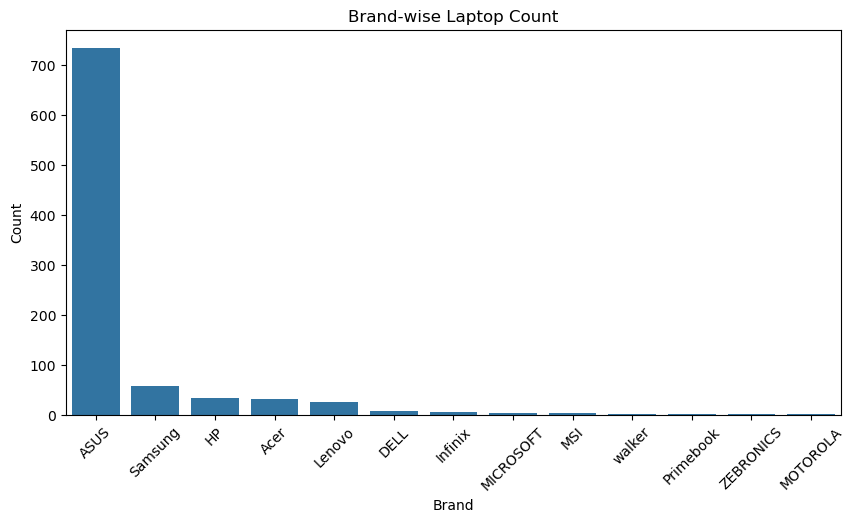

In [56]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="Brand_title", order=df["Brand_title"].value_counts().index)

plt.title("Brand-wise Laptop Count")
plt.xlabel("Brand")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()


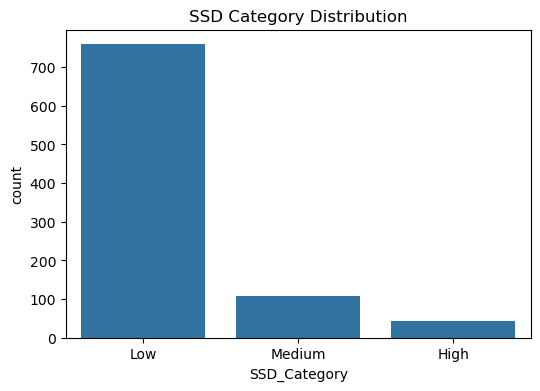

In [57]:
plt.figure(figsize=(6,4))
sns.countplot(x=df["SSD_Category"])
plt.title("SSD Category Distribution")
plt.show()

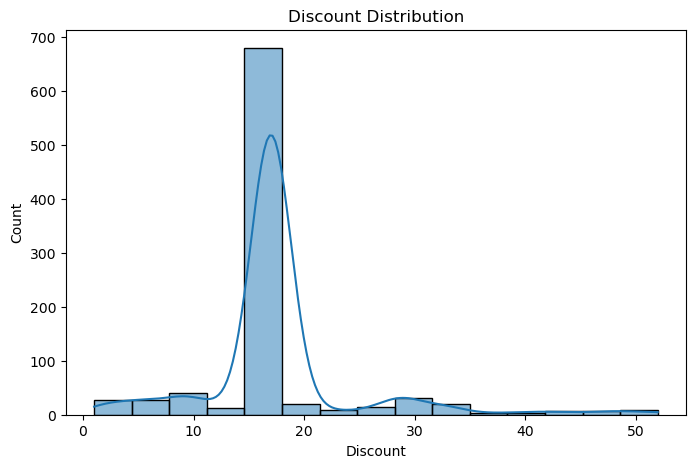

In [58]:
plt.figure(figsize=(8,5))
sns.histplot(df["Discount"], bins=15, kde=True)
plt.title("Discount Distribution")
plt.show()

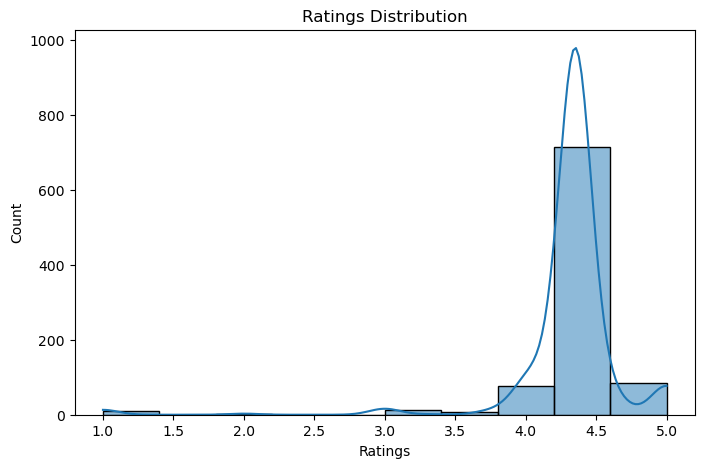

In [59]:
plt.figure(figsize=(8,5))
sns.histplot(df["Ratings"], bins=10, kde=True)
plt.title("Ratings Distribution")
plt.show()

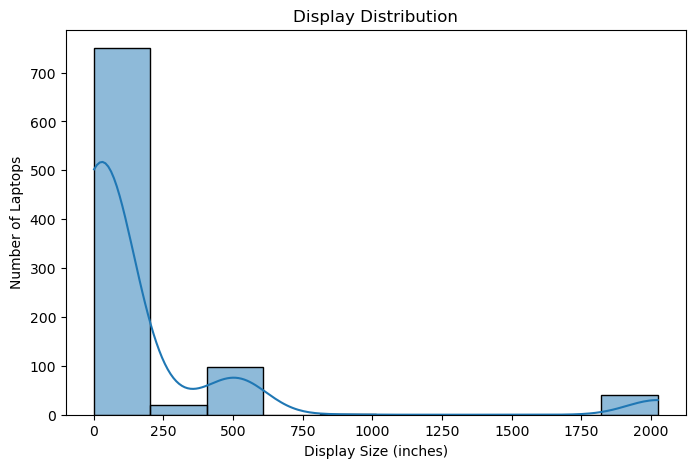

In [67]:
plt.figure(figsize=(8,5))
sns.histplot(df["Display"], bins=10, kde=True)
plt.title("Display Distribution")
plt.xlabel("Display Size (inches)")
plt.ylabel("Number of Laptops")
plt.show()

### Bivariate Analysis

### 1.  Brand_title vs Price

Objective: Compare the average price of laptops by brand.

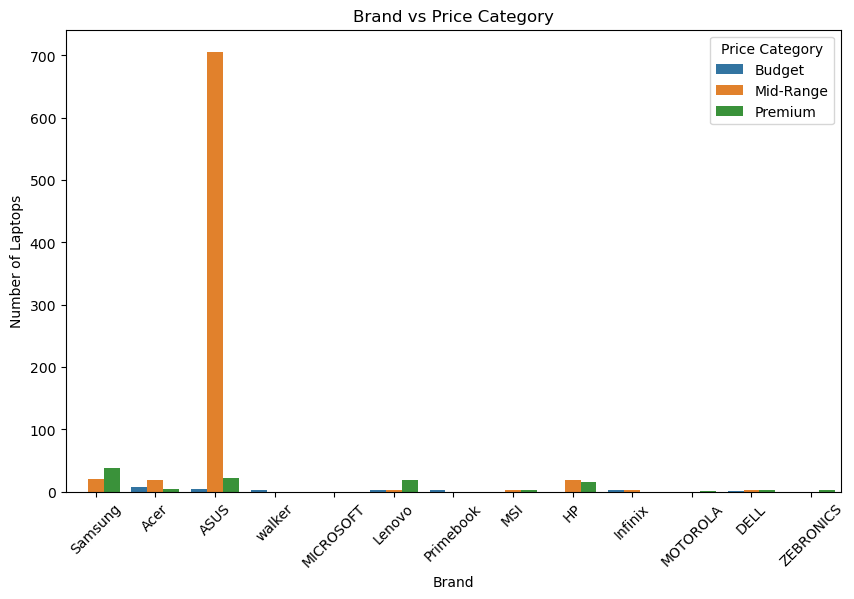

In [60]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="Brand_title",
    hue="Price_Category"
)

plt.title("Brand vs Price Category")
plt.xlabel("Brand")
plt.ylabel("Number of Laptops")
plt.xticks(rotation=45)
plt.legend(title="Price Category")
plt.show()

Asus offers laptops across all three price categories.
Asus,samsung has a strong presence in the Mid-Range category.
ASUS offers both Mid-Range and Premium laptops.
Budget laptops are concentrated among brands such as Acer, Infinix, and Ultimus (depending on your buget)

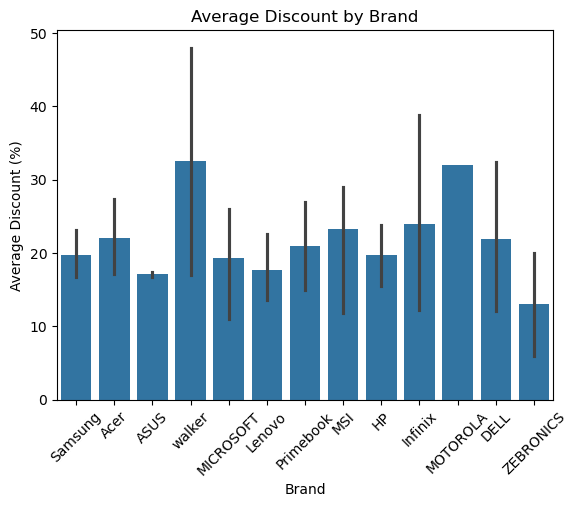

In [61]:
sns.barplot(
    data=df,
    x="Brand_title",
    y="Discount"
)

plt.title("Average Discount by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Discount (%)")
plt.xticks(rotation=45)
plt.show()

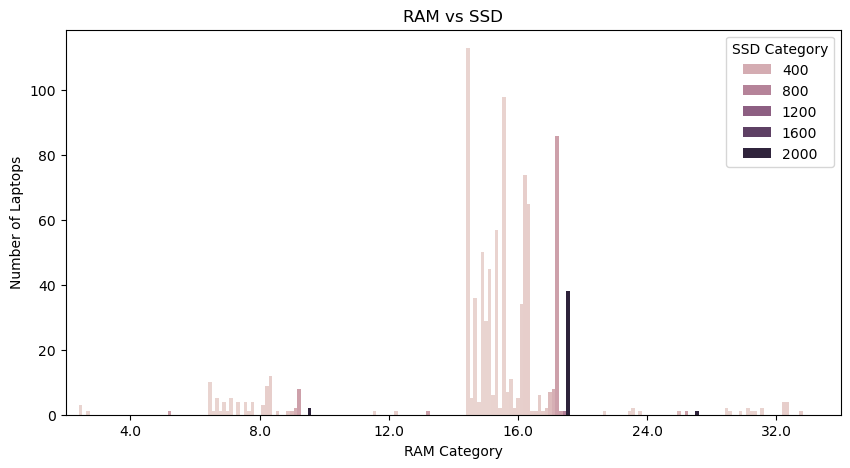

In [62]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="RAM",
    hue="SSD"
)

plt.title("RAM vs SSD")
plt.xlabel("RAM Category")
plt.ylabel("Number of Laptops")
plt.legend(title="SSD Category")
plt.show()

- Laptops with 8 GB RAM are commonly paired with 256 GB or 512 GB SSDs.
- 16 GB RAM laptops most frequently come with 512 GB SSDs.
- 32 GB RAM laptops are usually equipped with 1 TB (1024 GB) SSDs.

### Multivariate Analysis


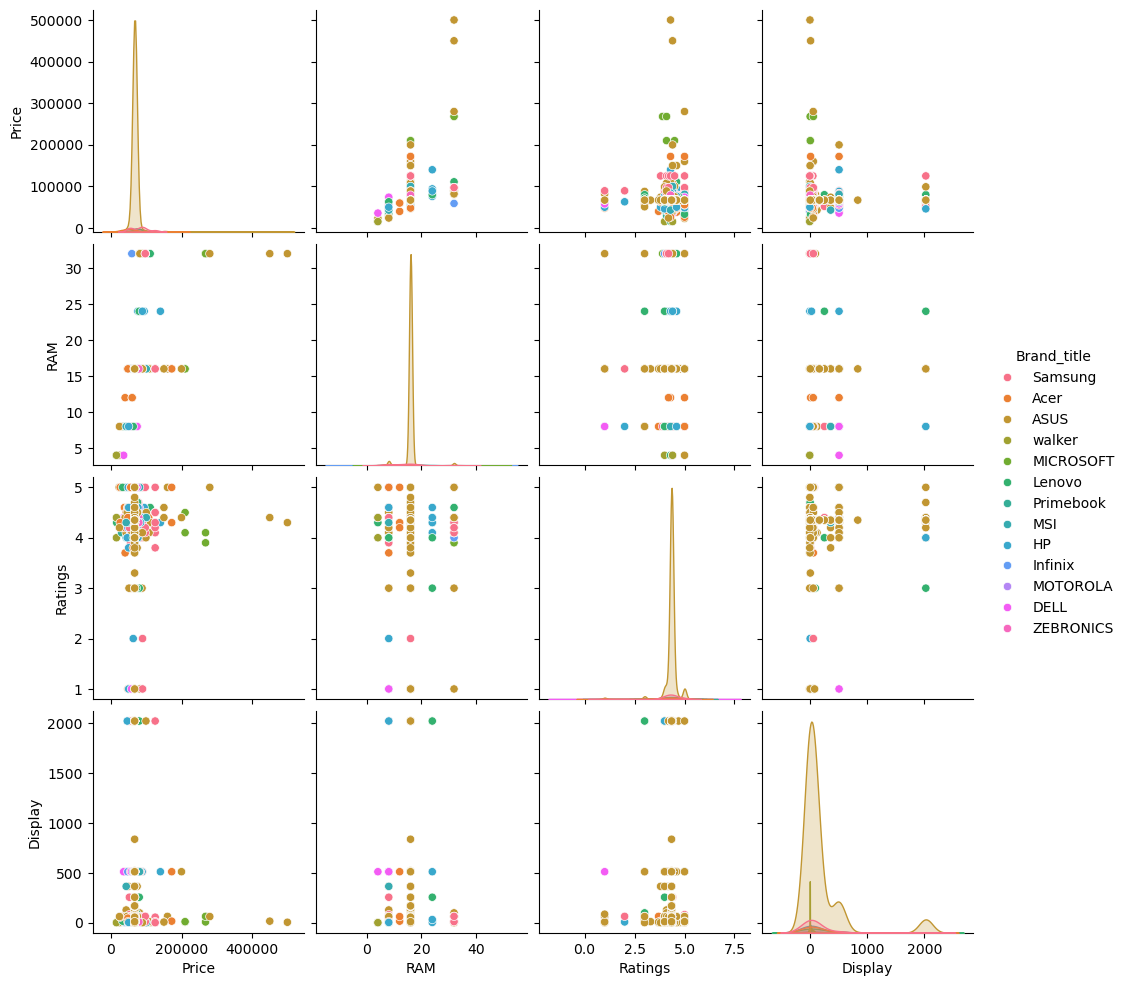

In [64]:
sns.pairplot(
    df,
    vars=["Price", "RAM", "Ratings","Display"],
    hue="Brand_title"
)

plt.show()

- Premium brands generally have higher prices, larger RAM, and better display sizes.
- Mid-range brands offer a balance between price and ratings.
- Brands with 16 GB or 32 GB RAM are mostly in the higher price segment.
- Display size varies only slightly across brands, while price and RAM show larger differences.
- Highly rated laptops are available across multiple brands, indicating that customer satisfaction is not determined by price alone.

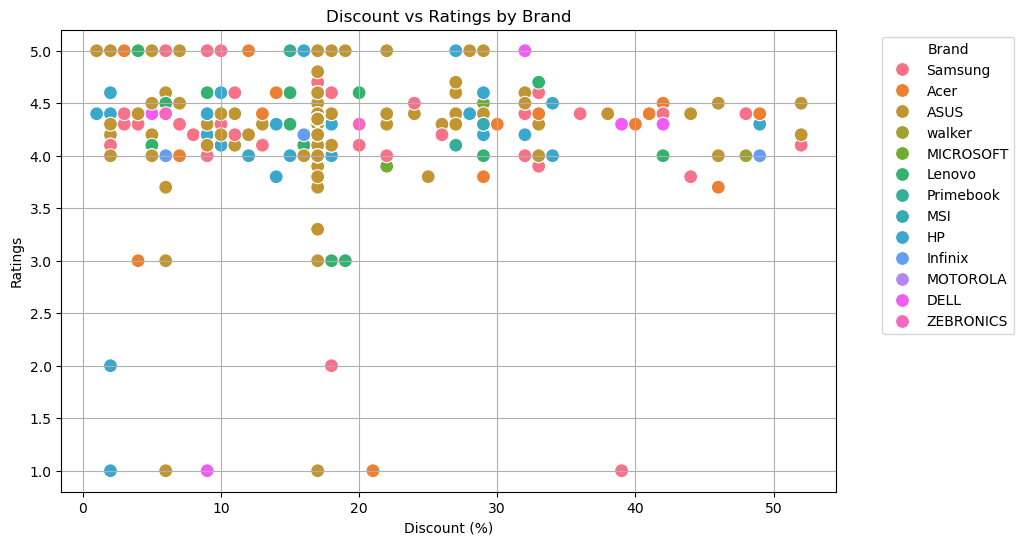

In [57]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Ratings",
    hue="Brand_title",
    s=100
)

plt.title("Discount vs Ratings by Brand")
plt.xlabel("Discount (%)")
plt.ylabel("Ratings")
plt.legend(title="Brand", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.show()

- Each point represents one laptop.
- The x-axis shows the Discount (%).
- The y-axis shows the Customer Rating.
- Different colors (in the first plot) represent different Brand_Title values, making it easy to compare brands and identify patterns or outliers.

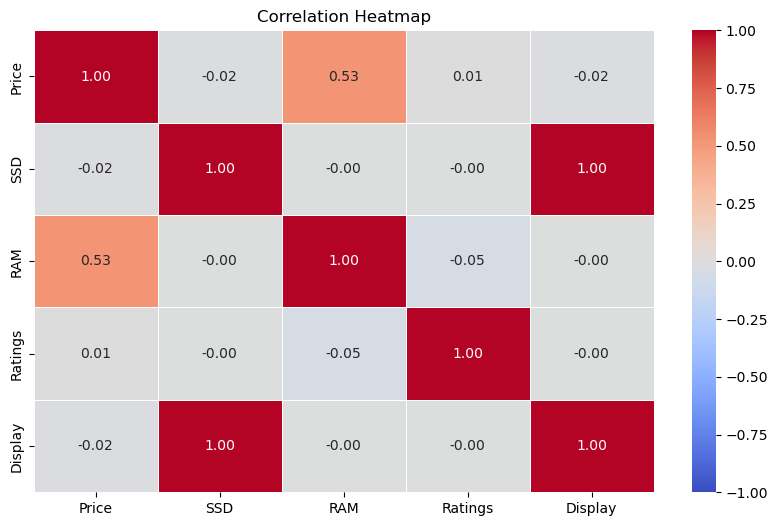

In [62]:
correlation_matrix = df[['Price', 'SSD', 'RAM', 'Ratings', 'Display']].corr()

# Plot the correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()